In [519]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

%matplotlib inline

In [520]:
df = pd.read_csv("../data/AusApparalSales4thQrt2020.csv")

In [521]:
df.head()

,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500


In [522]:
df.tail()

,Date,Time,State,Group,Unit,Sales
7555,30-Dec-2020,Afternoon,TAS,Seniors,14,35000
7556,30-Dec-2020,Evening,TAS,Kids,15,37500
7557,30-Dec-2020,Evening,TAS,Men,15,37500
7558,30-Dec-2020,Evening,TAS,Women,11,27500
7559,30-Dec-2020,Evening,TAS,Seniors,13,32500


In [523]:
df.shape

(7560, 6)

In [524]:
df.columns

Index(['Date', 'Time', 'State', 'Group', 'Unit', 'Sales'], dtype='str')

In [525]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    7560 non-null   str  
 1   Time    7560 non-null   str  
 2   State   7560 non-null   str  
 3   Group   7560 non-null   str  
 4   Unit    7560 non-null   int64
 5   Sales   7560 non-null   int64
dtypes: int64(2), str(4)
memory usage: 354.5 KB


In [526]:
df.describe()

,Unit,Sales
count,7560.000000,7560.000000
mean,18.005423,45013.558201
std,12.901403,32253.506944
min,2.000000,5000.000000
25%,8.000000,20000.000000
50%,14.000000,35000.000000
75%,26.000000,65000.000000
max,65.000000,162500.000000


In [527]:
df.isnull().sum()

Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

In [528]:
df.duplicated().sum()

np.int64(0)

In [529]:
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False)
group_sales = df.groupby("Group")["Sales"].sum().sort_values(ascending=False)
time_sales = df.groupby("Time")["Sales"].sum().sort_values(ascending=False)

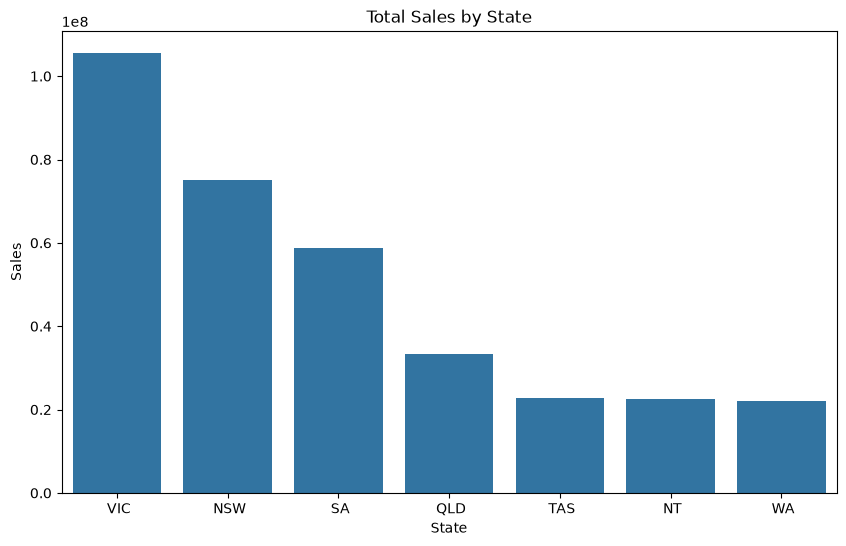

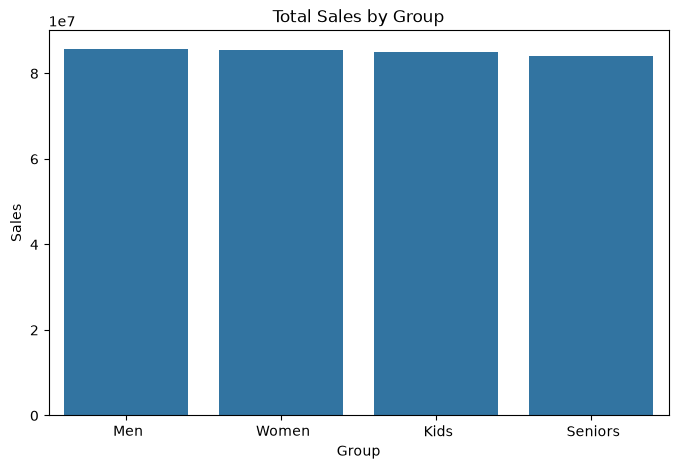

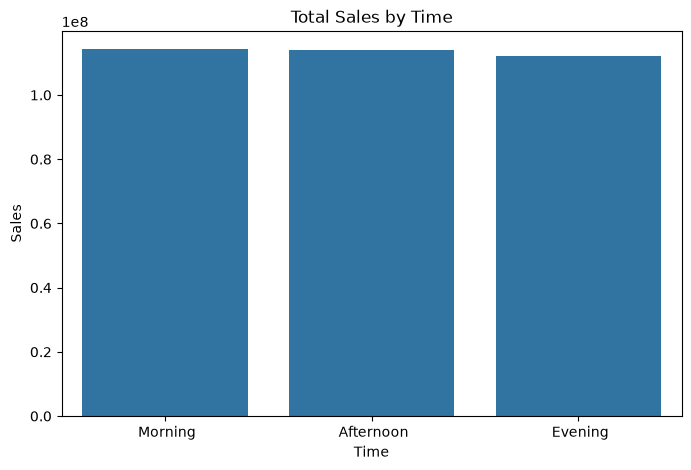

In [530]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=state_sales.index,
    y=state_sales.values
)
plt.title("Total Sales by State")
plt.xlabel("State")
plt.ylabel("Sales")
plt.show()

plt.figure(figsize=(8,5))
sns.barplot(
    x=group_sales.index,
    y=group_sales.values
)
plt.title("Total Sales by Group")
plt.xlabel("Group")
plt.ylabel("Sales")
plt.show()

plt.figure(figsize=(8,5))
sns.barplot(
    x=time_sales.index,
    y=time_sales.values
)
plt.title("Total Sales by Time")
plt.xlabel("Time")
plt.ylabel("Sales")
plt.show()

In [531]:
df["Date"] = pd.to_datetime(df["Date"])

In [532]:
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Year"] = df["Date"].dt.year
df["Weekday"] = df["Date"].dt.day_name()
df["Quarter"] = df["Date"].dt.quarter
df["IsWeekend"] = df["Date"].dt.weekday >= 5
df.head()

,Date,Time,State,Group,Unit,Sales,Month,Day,Year,Weekday,Quarter,IsWeekend
0,2020-10-01,Morning,WA,Kids,8,20000,10,1,2020,Thursday,4,False
1,2020-10-01,Morning,WA,Men,8,20000,10,1,2020,Thursday,4,False
2,2020-10-01,Morning,WA,Women,4,10000,10,1,2020,Thursday,4,False
3,2020-10-01,Morning,WA,Seniors,15,37500,10,1,2020,Thursday,4,False
4,2020-10-01,Afternoon,WA,Kids,3,7500,10,1,2020,Thursday,4,False


In [533]:
df = df.drop(columns=["Date", "Year", "Quarter"])

In [534]:
df = pd.get_dummies(
    df,
    columns=["State", "Group", "Time", "Weekday"],
    drop_first=True
)
df.head()

,Unit,Sales,Month,Day,IsWeekend,State_ NT,State_ QLD,State_ SA,State_ TAS,State_ VIC,...,Group_ Seniors,Group_ Women,Time_ Evening,Time_ Morning,Weekday_Monday,Weekday_Saturday,Weekday_Sunday,Weekday_Thursday,Weekday_Tuesday,Weekday_Wednesday
0,8,20000,10,1,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False
1,8,20000,10,1,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False
2,4,10000,10,1,False,False,False,False,False,False,...,False,True,False,True,False,False,False,True,False,False
3,15,37500,10,1,False,False,False,False,False,False,...,True,False,False,True,False,False,False,True,False,False
4,3,7500,10,1,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [535]:
X = df.drop("Sales", axis=1)
Y = df["Sales"]

In [536]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

In [537]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [538]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [539]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](21,)","[157500., 0., 0.,..., 0., 0., 0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5000
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,21
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](21,)","[45.08,44.75,38.86,...,12.34, 6.44, 0. ]"


In [540]:
predictions = model.predict(X_test)

In [541]:
comparison = pd.DataFrame({
    "Actual Sales": Y_test,
    "Predicted Sales": predictions
})

comparison.head(10)

,Actual Sales,Predicted Sales
6882,30000,30000.0
6237,25000,25000.0
263,37500,37500.0
694,17500,17500.0
2264,32500,32500.0
2484,27500,27500.0
2266,32500,32500.0
5832,102500,102500.0
2926,30000,30000.0
1487,25000,25000.0


In [542]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mae = mean_absolute_error(Y_test, predictions)
mse = mean_squared_error(Y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"R-squared (R2 ): {r2}")

Mean Absolute Error (MAE): 1.2384226037375383e-10
Mean Squared Error (MSE): 2.4230806837437602e-20
Root Mean Squared Error (RMSE): 1.5566247729442572e-10
R-squared (R2 ): 1.0


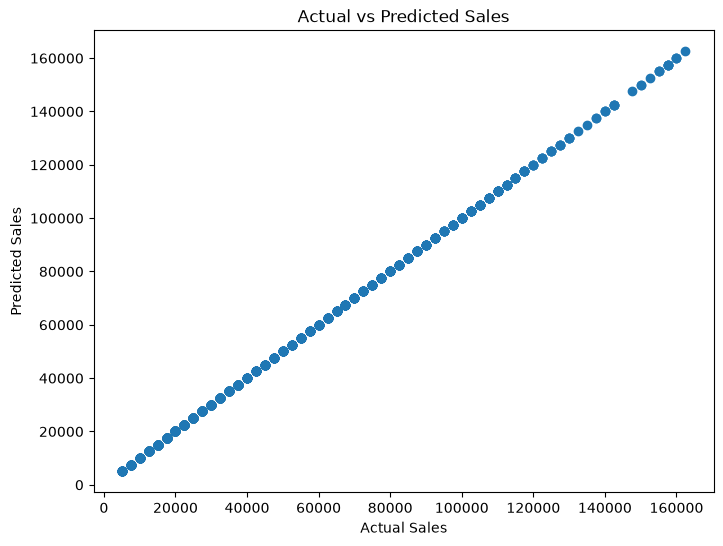

In [543]:
plt.figure(figsize=(8,6))

plt.scatter(Y_test, predictions)

plt.xlabel("Actual Sales")

plt.ylabel("Predicted Sales")

plt.title("Actual vs Predicted Sales")

plt.show()

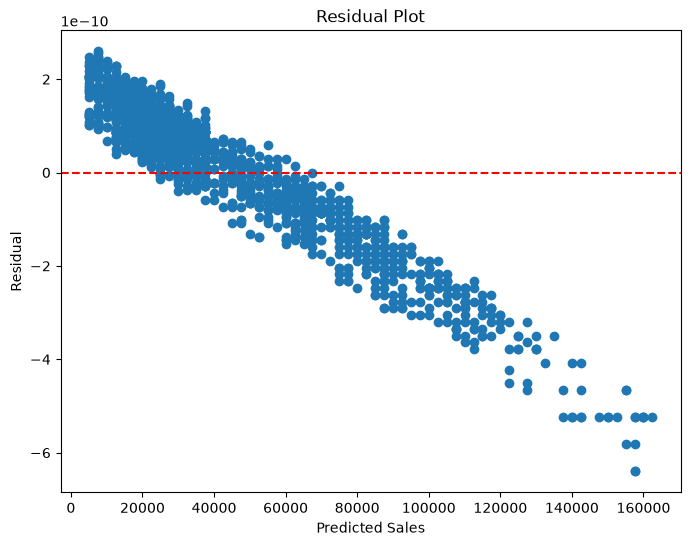

In [544]:
residuals = Y_test - predictions

plt.figure(figsize=(8,6))

plt.scatter(predictions, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Sales")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.show()

In [545]:
(df["Sales"] / df["Unit"]).unique()

array([2500.])

In [546]:
df[["Unit", "Sales"]].corr()

,Unit,Sales
Unit,1.0,1.0
Sales,1.0,1.0


<Axes: xlabel='Unit', ylabel='Sales'>

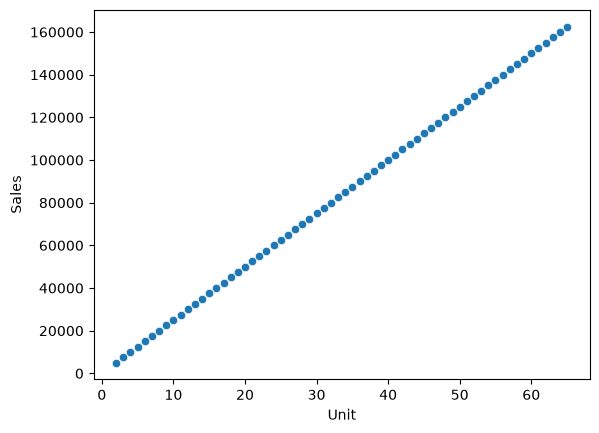

In [547]:
sns.scatterplot(
    x=df["Unit"],
    y=df["Sales"]
)

In [548]:
import pickle

with open("../models/sales_prediction_model.pkl", "wb") as f:
    pickle.dump(model, f)